<a href="https://colab.research.google.com/github/liminovna/bank_reviews_EDA/blob/main/EDA_banks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Введение

В этом блокноте приведен пример разведочного анализа данных. В ходе него мы описали, какие данные нам доступны, предположили, какой смысл они несут, обнаружили пропажи в данных и их закономерности, исследовали аномалии и корреляции, снабдили исследование визуализациями и метриками.

В качестве источника использовался датасет с отзывами на банки, доступный на hugging face ([ссылка на датасет](https://huggingface.co/datasets/Romjiik/Russian_bank_reviews)). Это реальные данные, собранные с сайта banki.ru за период с 2022 по 2023 год пользователем hugging face.

In [ ]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
import re
from scipy.stats import kendalltau, bootstrap

sns.set_theme()

In [ ]:
def rating_gini_coeff(data: np.array) -> float:
    """
    Функция принимает на вход numpy.Series -- список неагрегированных значений -- и возвращает единственное число -- коэффициент сбалансированности.
    Коэффициент представляет собой обратное значение коэффициента Джини
    """
    rating_counts = data[data.isin([1,5])].value_counts().sort_index() / data[data.isin([1,5])].count()
    return (1 - (rating_counts.apply(lambda x: x**2).sum())) / rating_counts.apply(lambda x: x**2).sum()

def tau_statistic(x: np.array, y: np.array, axis=-1):
    """
    Функция считает коэффициент корреляции Кенделла для двух переменных
    """
    return kendalltau(x, y, axis=axis).statistic

# Загрузка данных

In [ ]:
# загрузка данных с hugging face
df = pd.read_csv("hf://datasets/Romjiik/Russian_bank_reviews/final_review_dataset_extended.csv", index_col=0)
df.head()

,bank,type,user_name,review_title,review,review_dttm,review_views,review_comments,rating_value,Вежливые сотрудники,Доступность и поддержка,Прозрачные условия,"Удобство приложения, сайта",review_len,review_len_in_tokens
1,Россельхозбанк,Person,user-430412136020,Открытие счета ИП,Добрый день! Я являюсь ИП и стоял перед выборо...,2023-05-02,773,0,5,3.0,3.0,3.0,3.0,171.0,363.0
2,Россельхозбанк,Person,user-60268947545,Спасибо за помощь,Здравствуйте! Достаточно давно являюсь клиенто...,2023-04-02,560,0,5,3.0,3.0,3.0,3.0,66.0,149.0
3,Банк ДОМ.РФ,Person,user-294212759595,Отличный сервис,"Здравствуйте,являюсь клиентом банка с ноября 2...",2023-03-02,737,1,5,3.0,3.0,3.0,3.0,70.0,164.0
4,Альфа-Банк,Person,user-841712733484,Блокировка денежных средств,14 января 2023 года была попытка перевода дене...,2023-01-02,627,3,1,NaN,NaN,NaN,NaN,170.0,337.0
5,Банк «Открытие»,Person,NaN,Хамство сотрудников Открытия,"У меня сложилось устойчивое впечатление, что в...",2023-01-02,517,31,1,1.0,1.0,1.0,1.0,106.0,210.0


In [ ]:
# краткая сводка по датасету
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 12392 entries, 1 to 12392
Data columns (total 15 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   bank                        12392 non-null  object 
 1   type                        12392 non-null  object 
 2   user_name                   12361 non-null  object 
 3   review_title                12388 non-null  object 
 4   review                      12392 non-null  object 
 5   review_dttm                 12392 non-null  object 
 6   review_views                12392 non-null  int64  
 7   review_comments             12392 non-null  int64  
 8   rating_value                12392 non-null  int64  
 9   Вежливые сотрудники         11377 non-null  float64
 10  Доступность и поддержка     11377 non-null  float64
 11  Прозрачные условия          11377 non-null  float64
 12  Удобство приложения, сайта  11377 non-null  float64
 13  review_len                  12392 no

Названия почти всех столбцов неоднозначно указывают, какой смысл несут данные в ней. Исключением здесь является столбец `review_len`: мы можем предположить, что это длина текста, но вопрос в том, как измеряется эта длина. Предположим, что `review_len` -- это количество непрерывных последовательностей букв и цифр в тексте. Проверим это в ячейке ниже:

In [ ]:
# проверка предположения о том, что review_len = кол-во последовательностей цифр и букв
(df['review_len'] == df['review'].apply(lambda s: len(re.findall('[а-яА-ЯёЁ0-9]+', s)))).value_counts()

,count
True,12392


Результат говорит в пользу нашего предположения: значения в столбце совпадают с количеством непрерывных последовательностей букв и цифр, найденных с помощью регулярного выражения.

Другим исключением является столбец `type`, который в датасете принимает только одно значение -- 'Person'. Возможно, в датасете собраны только отзывы, оставленные пользователями, а ответы от ботов исключены.

In [ ]:
# возможные значения в столбце type
# df['type'].unique()

Таким образом, в датасете нам доступны
- сам текст отзыва (`review`, строка),
- его заголовок (`review_title`, строка),
- ник автора (`user_name`, строка),
- тип автора (`type`, строка),
- дата отзыва(`review_dttm`, строка),
- название банка (`bank`, строка),
- длина отзыва в словах -- последовательность букв и цифр (`review_len`, целое число)
- длина отзыва в токенах (`review_len_in_tokens`, дробное число),
- количество просмотров отзыва (`review_views`, дробное число),
- количество ответов к отзыву (`review_views`, дробное число),
- общая оценка банку (`rating_value`, целое число),
- численные оценки банку по конкретным критериям (дробное число).

Всего датасет содержит 12 392 отзыва.

Сравнивая датасет с интерфейсом сайта мы можем предположить, что собранные с сайта данные (заголовок, текст отзыва, автор, дата, название банка, рейтинг) автор датасета дополнил информацией о длине отзыва и численной оценкой отдельных критериев. Кажется, что критерии -- результат аспектного сентимент-анализа, проведенного автором, поэтому предлагаю исключить эти столбцы из дальнейшего анализа вместе с `type` (принимает всего одно значение для всех строк и не несет смысловой нагрузки).

In [ ]:
# удаляем ненужные столбцы
df.drop(columns=[
    'type',
    'Вежливые сотрудники',
    'Доступность и поддержка',
    'Прозрачные условия',
    'Удобство приложения, сайта',
    'review_len_in_tokens'
],  inplace=True)

# Проверка качества данных

В этом разделе мы вычислим основные статистики, найдем выбросы, проверим дубли, уникальные и пропущенные значения и исследуем возможные причины пропусков.

## Описательная статистика и выбросы

In [ ]:
# изменяем тип данных для столбца с датой отзыва
df['review_dttm'] = pd.to_datetime(df['review_dttm'])

In [ ]:
# краткая описательная статистика по количественным признакам, одному порядковому признаку (rating_value) и дате
df.describe()

,review_dttm,review_views,review_comments,rating_value,review_len
count,12392,12392.000000,12392.000000,12392.000000,12392.000000
mean,2022-11-19 13:35:45.125887488,1548.677130,2.070771,2.845465,149.578518
min,2022-01-12 00:00:00,326.000000,0.000000,1.000000,13.000000
25%,2022-11-14 00:00:00,1027.000000,0.000000,1.000000,68.000000
50%,2022-11-29 00:00:00,1186.000000,1.000000,2.000000,110.000000
75%,2022-12-24 00:00:00,1487.000000,3.000000,5.000000,190.000000
max,2023-12-01 00:00:00,78811.000000,50.000000,5.000000,945.000000
std,NaN,2107.490696,2.939095,1.875967,114.800003


In [ ]:
print('Длительность покрытого периода:')
df['review_dttm'].max() - df['review_dttm'].min()

Длительность покрытого периода:


Timedelta('688 days 00:00:00')

Видим, что в столбце `review_views` данные скошены вправо. Рассмотрим выбросы.

Выбросы слева: 326.0 - 337.0 (3 точки)
Выбросы справа: 2177.0 - 78811.0 (1092 точки)


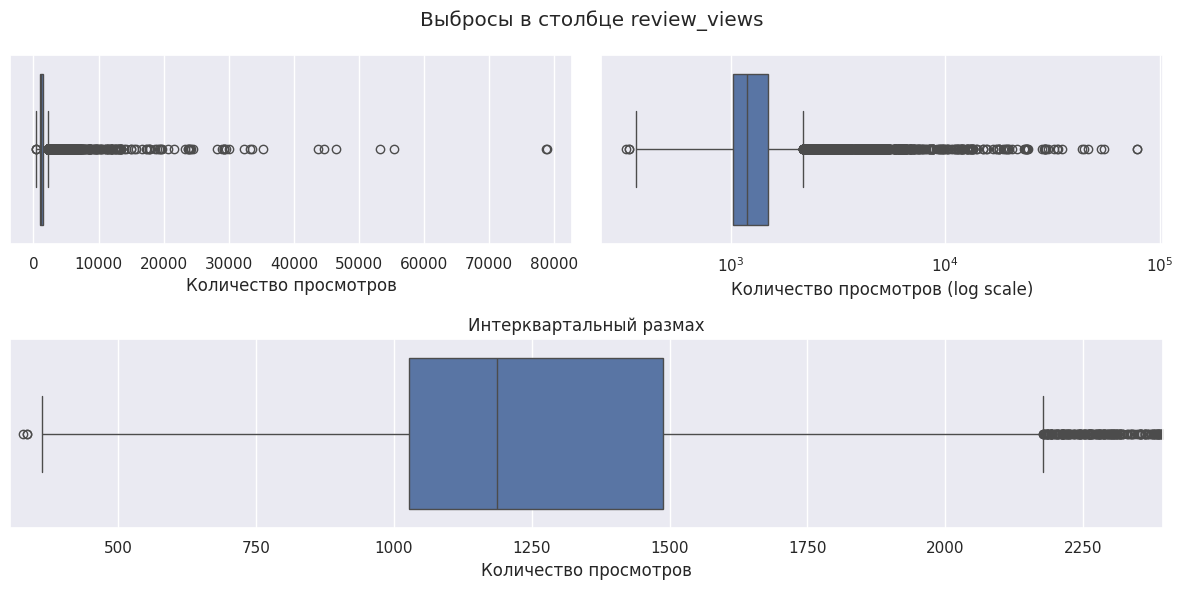

In [ ]:
# @title 📊 Визуализация выбросов (график)

# Вычисление IQR
q25 = df['review_views'].quantile(0.25)
q75 = df['review_views'].quantile(0.75)
IQR = q75 - q25
outliers_min_threshold = q25 - 1.5*IQR
outliers_max_threshold = q75 + 1.5*IQR

print(f"Выбросы слева: {float(df['review_views'].min())} - {outliers_min_threshold} ({len(df[df['review_views']<outliers_min_threshold])} точки)")
print(f"Выбросы справа: {outliers_max_threshold} - {float(df['review_views'].max())} ({len(df[df['review_views']>outliers_max_threshold])} точки)")

# Визуализация
plt.figure(figsize=(12, 6))

ax1 = plt.subplot(221)
sns.boxplot(x=df['review_views'], ax=ax1)
ax1.set(xlabel='Количество просмотров')

ax2 = plt.subplot(222)
sns.boxplot(x=df['review_views'], ax=ax2)
ax2.set_xscale('log')
ax2.set(xlabel='Количество просмотров (log scale)')

ax3 = plt.subplot(212)
sns.boxplot(x=df['review_views'], ax=ax3)
ax3.set(xlabel='Количество просмотров')
ax3.set_xlim(outliers_min_threshold * 0.9, outliers_max_threshold * 1.1)
ax3.set_title('Интерквартальный размах')

plt.suptitle('Выбросы в столбце review_views')
plt.tight_layout();

Более 1 тыс. отзывов получили экстремально большое количество просмотров -- 2177 и больше.

## Уникальные и пропущенные значения, дубли

In [ ]:
# количество уникальных значений
df.nunique()

,0
bank,86
user_name,11447
review_title,10158
review,12392
review_dttm,87
review_views,2440
review_comments,37
rating_value,5
review_len,580


Из таблицы выше видим, что на >12 тыс. записей приходится только 87 уникальных дат, при том, что пропусков и выбросов нет, что вызывает дополнительные сомнения в качестве данных.

In [ ]:
# проверяем дубли по сочетанию автор-банк-дата-текст отзыва
df[df.duplicated(['user_name', 'bank', 'review_dttm', 'review'])]

,bank,user_name,review_title,review,review_dttm,review_views,review_comments,rating_value,review_len


Дублей по сочетанию автор-банк-дата-текст отзыва не обнаружено.

In [ ]:
# количество пропущенных значений
df.isna().sum()

,0
bank,0
user_name,31
review_title,4
review,0
review_dttm,0
review_views,0
review_comments,0
rating_value,0
review_len,0


### Пропущенные ники авторов (`user_name`)

Для 31 отзыва в датасете пропущены авторы. На сайте вместо никнеймов для этих отзывов отображается значение "Гость", поэтому делаем вывод, что пропуски связаны с тем, что авторы не зарегистрированы в системе и соответственно не имеют никнеймов.

In [ ]:
# примеры отзывов без указания автора
df[df['user_name'].isna()].sample(5)

,bank,user_name,review_title,review,review_dttm,review_views,review_comments,rating_value,review_len
10095,Сбербанк,NaN,Машиностроитель Зарплатный Плюс,Ну что ж.... Начались чудесные метаморфозы в С...,2022-11-22,931,3,3,195.0
8875,Банк ЗЕНИТ,NaN,Благодарность сотрудникам за неравнодушие,Здравствуйте! Хочу сказать слова благодарности...,2022-11-27,1247,1,5,117.0
8270,Россельхозбанк,NaN,Благодарность сотрудникам ДО в Куркино,Здравствуйте. Хочу оставить благодарность сотр...,2022-11-30,1282,0,5,141.0
9843,Хоум Кредит Банк,NaN,Нарушение моих прав как потребителя,"Здрасьт, я написала отказ от страховки 24 Октя...",2022-11-23,1012,1,1,113.0
1661,Почта Банк,NaN,Неправильный график на сайте,Обратился 05.01.23 в отделение по адресу Москв...,2023-05-01,3747,5,1,58.0


### Пропущенные заголовки отзывов (`review_title`)

Также в датасете есть 4 отзыва, для которых не указан заголовок. Поиск отзывов на самом сайте обнаружил, что всех их объединяет то, что там они состоят всего из одного слова на латинице. Чтобы делать предположения о причинах полезно знать, как собирались и обрабатывались данные, но мы такой информацией не располагаем.

Вот ссылки на 4 комментария с пропущенными заголовками:
- "Cashback": https://www.banki.ru/services/responses/bank/response/10778570/
- "Swift": https://www.banki.ru/services/questions-answers/question/459995/
- "Delete": https://www.banki.ru/services/responses/bank/response/10771232/
- "Otkritie": https://www.banki.ru/services/responses/bank/response/10770729/



In [ ]:
# отзывы с пропущенными заголовками
df[df['review_title'].isna()]

,bank,user_name,review_title,review,review_dttm,review_views,review_comments,rating_value,review_len
9038,МТС Банк,DLushkin,NaN,При подключении автоплатежа из приложения банк...,2022-11-26,1279,2,1,78.0
9128,Уралсиб,user7536361,NaN,"Здравствуйте, я хотел узнать информацию по пер...",2022-11-25,1123,0,3,119.0
10789,Хоум Кредит Банк,Malisch-ka,NaN,Добрый день. Не могу понять в приложение где в...,2022-11-18,956,2,5,57.0
10924,Банк «Открытие»,user-703611986498,NaN,Получила карту кредитную в отделении. Очень пр...,2022-11-17,1057,0,5,42.0


Здесь также следовало бы проверить названия банков на существование разных вариантов написания (например, Сбер Банк, Сбербанк, Сбер), но на сайте можно оставить отзыв только на банк из списка, который уже "дедублирован", поэтому в такой проверке нет необходимости.

# Исследование данных

## Распределение оценок

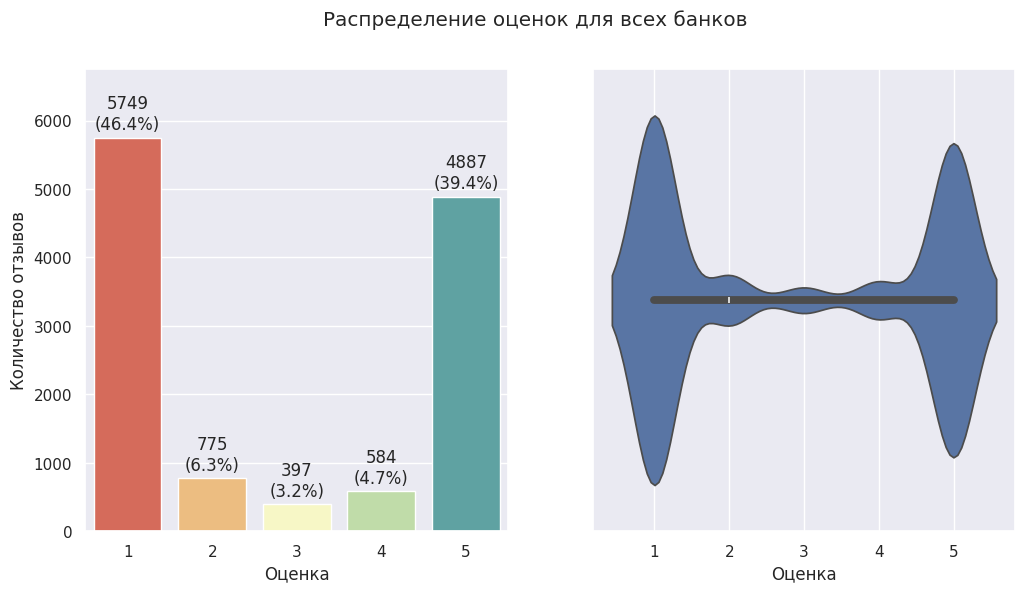

In [ ]:
# @title 📊 Распределение оценок (график)
unique_vals = list(range(min(df['rating_value']), max(df['rating_value'])+1))

counts = df['rating_value'].value_counts().sort_index()

fig, ax = plt.subplots(1, 2, figsize=(12, 6))

# countplot
sns.countplot(
    df,
    x="rating_value",
    order=unique_vals,
    hue='rating_value',
    palette=sns.color_palette('Spectral',5),
    # alpha=0.9,
    legend=False,
    ax=ax[0]
)

# заголовки
ax[0].set_xlabel('Оценка')
ax[0].set_ylabel('Количество отзывов')

# надписи
for container in ax[0].containers:
    labels = [f"{int(v.get_height())}\n({v.get_height() / len(df):.1%})" if v.get_height() > 0 else "" for v in container]
    ax[0].bar_label(container, labels=labels, label_type="edge", padding=3)

ax[0].set_ylim(0, max(counts)+1000);


# violinplot
sns.violinplot(df, x='rating_value',ax=ax[1])

# заголовки
ax[1].set_xlabel('Оценка')

plt.suptitle('Распределение оценок для всех банков');

In [ ]:
# доля крайних оценок
ers_total = df[df['rating_value'].isin([1,5])]['rating_value'].count()/len(df)
print('Доля крайних оценок (ERS):', f'{ers_total:.1%}', sep='\n')

Доля крайних оценок (ERS):
85.8%


In [ ]:
# измерим сбалансированность крайних оценок используя Gini coefficient
balance_total = rating_gini_coeff(df['rating_value'])
print('Коэффициент сбалансированности (balance):', round(balance_total,2), ', где 0 -- абсолютный дизбаланс, 1 -- оценки распределены поровну', sep='\n')

Коэффициент сбалансированности (balance):
0.99
, где 0 -- абсолютный дизбаланс, 1 -- оценки распределены поровну


Рейтинги имеют полярный характер: 86% принимают имеют либо минимальное, либо максимальное значение (то есть либо 1, либо 5), и распределены почти поровну (коэффициент сбалансированности близок к 1) -- 46.4% резко отрицательных против 39.4% резко положительных, а остальные 14% занимают более умеренные оценки.

Для измерения полярности оценок и сбалансированности крайних оценок мы ввели две метрики -- Extreme rating ratio (ERS) и Balance соответственно.

- ERS -- доля крайних оценок, рассчитывается как сумма оценок 1 и 5, деленная на общее количество оценок. 1 -- все оценки принимают только крайние значения, 0 -- оценки распределены между "умеренными" значениями.
- Balance -- коэффициент сбалансированности, основанный на коэффициенте Джини. Значение близкое к 1 означает, что оценок 1 и 5 поровну; 0 означает, что из двух возможных крайних оценок 1 и 5 пользователи поставили только 1 или только 5.

In [ ]:
# размер топа по количеству оценок
n = 10

# топ-n
topn = df['bank'].value_counts().head(n)

In [ ]:
print(f'Топ-{n} по количеству отзывов:')
topn

Топ-10 по количеству отзывов:


,count
bank,
Тинькофф Банк,1551
Совкомбанк,1501
ВТБ,1275
Хоум Кредит Банк,978
Альфа-Банк,861
Россельхозбанк,859
Сбербанк,680
Газпромбанк,511
Банк «Открытие»,510


In [ ]:
print(f'Процент отзывов, оставленных для топ-{n} банков:', f"{len(df[df['bank'].isin(topn.index)])/len(df)*100:.2f}%")

Процент отзывов, оставленных для топ-10 банков: 74.42%


In [ ]:
print(f'Антитоп-{n} по количеству отзывов:')
df['bank'].value_counts().tail(n)

Антитоп-10 по количеству отзывов:


,count
bank,
Кредит Урал Банк,1
Металлинвестбанк,1
Трансстройбанк,1
Банк Раунд,1
БыстроБанк,1
Венец,1
Солид Банк,1
Банк «Приморье»,1
Реалист Банк,1


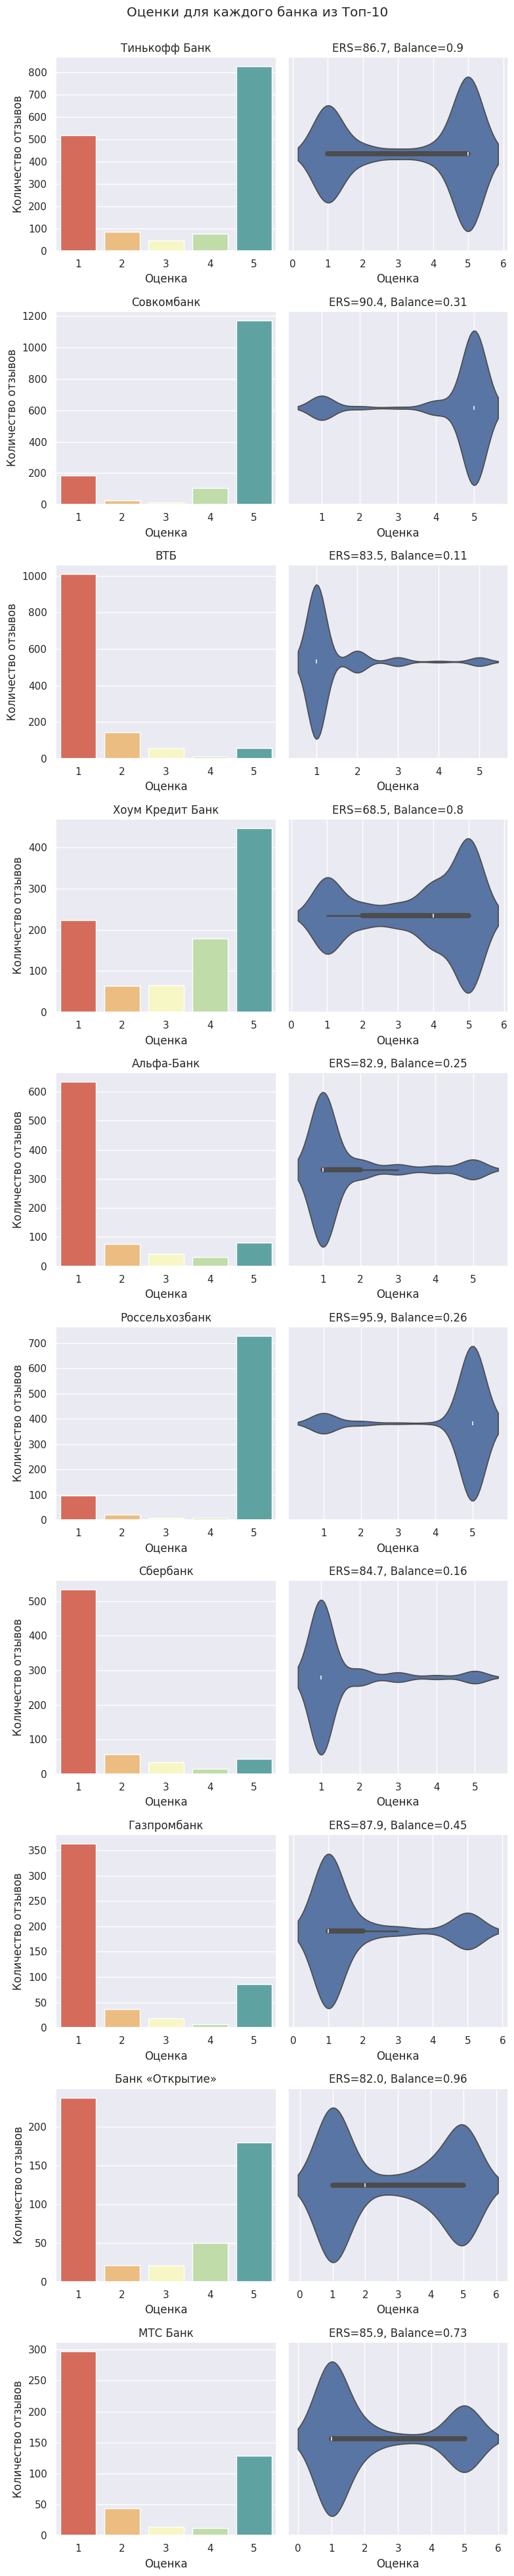

In [ ]:
# @title 📊 График с распределением оценок для Топ-10 банков (график)

fig, ax = plt.subplots(n,2, figsize=(2*4, n*4))

ERSs = []
balances = []

for i in range(n):
    cur_bank_df = df[df['bank'] == topn.index[i]]
    # countplot
    sns.countplot(
        cur_bank_df,
        x="rating_value",
        order=unique_vals,
        hue='rating_value',
        palette=sns.color_palette('Spectral',5),
        # alpha=0.9,
        legend=False,
        ax=ax[i][0]
    )

    ax[i][0].set(ylabel='Количество отзывов', xlabel='Оценка')
    ax[i][0].set_title(f'{topn.index[i]}')

    # violinplot
    sns.violinplot(cur_bank_df, x='rating_value',ax=ax[i][1])

    extreme_rating_share = round(cur_bank_df[cur_bank_df['rating_value'].isin([1,5])]['rating_value'].count() / cur_bank_df['rating_value'].count() * 100,1) # процент крайних оценок
    balance_coeff = round(rating_gini_coeff(cur_bank_df['rating_value']),2) # коэффициент сбалансированности

    ERSs.append(extreme_rating_share)
    balances.append(balance_coeff)

    ax[i][1].set(xlabel='Оценка')
    ax[i][1].set_title(f'ERS={extreme_rating_share}, Balance={balance_coeff}')

plt.suptitle(f'Оценки для каждого банка из Топ-{n}')
plt.tight_layout(rect=[0, 0, 1, 0.98]);

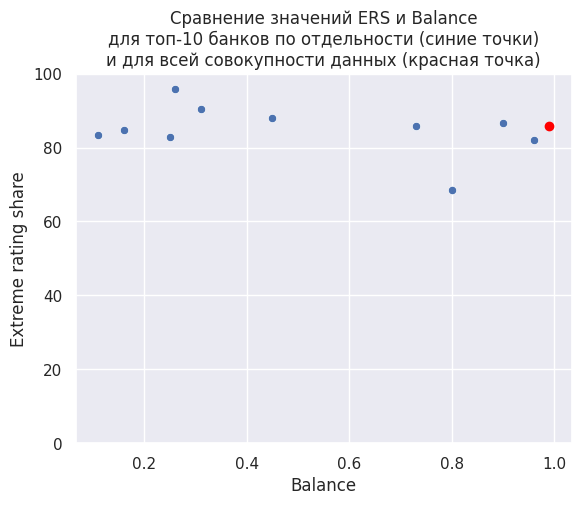

In [ ]:
# @title 📊 Сравнение значений ERS и Balance (график)
topn_ratings = pd.DataFrame(index=topn.index, data={'ers': ERSs, 'balance': balances})

ax = sns.scatterplot(data=topn_ratings, y='ers', x='balance')
ax.set_ylim(0, 100)

extreme_rating_share_total = round(df[df['rating_value'].isin([1,5])]['rating_value'].count() / df['rating_value'].count() * 100,1) # процент крайних оценок
balance_coeff_total = round(rating_gini_coeff(df['rating_value']),2) # коэффициент сбалансированности

ax.scatter(x=balance_coeff_total, y=extreme_rating_share_total, color='red')

ax.set(ylabel='Extreme rating share', xlabel='Balance')
plt.title('Сравнение значений ERS и Balance\nдля топ-10 банков по отдельности (синие точки)\nи для всей совокупности данных (красная точка)');

Рассматривая распределения оценок для отдельных банков из топ-10, мы можем заметить, что оно отличается от того, что мы наблюдали для всех банков в совокупности. Изначально для всех банков оценки были распределены примерно поровну между 1 и 5, и форма violin plot больше была похожа на симметричную гантель, однако для значительной части отдельно взятых банков его форма больше напоминает молот, то есть большинство оценок сосредоточено вокруг уже одного крайнего значения, а не двух.

Такую картину мы можем описать с помощью двух упомянутых выше метрик: Extreme rating share (ERS) -- доля экстремальных оценок (1 и 5) -- и Balance -- коэффициент баланса экстремальных оценок. Так, для всех банков в совокупности ERS был равен 0.86, то есть 86% оценок были распределены между 1 и 5, а коэффициент баланса был близок к 1, то есть оценок 1 и 5 было примерно поровну. При рассмотрении банков по отедльности для большинства из них мы наблюдаем "перевес" в сторону одной из крайних оценок. Так, перевес в крайне положительные оценки наблюдается для Совкомбанка, Россельхозбанка, а в отрицательную -- для ВТБ, Альфабанка, Сбербанка, Газпромбанка и МТС Банка.

## Наиболее активные пользователи

In [ ]:
# считаем количества отзывов для каждого пользователя, исключив DELETED -- предположительно удаленные профили
user_review_counts = df['user_name'].value_counts().drop('DELETED')

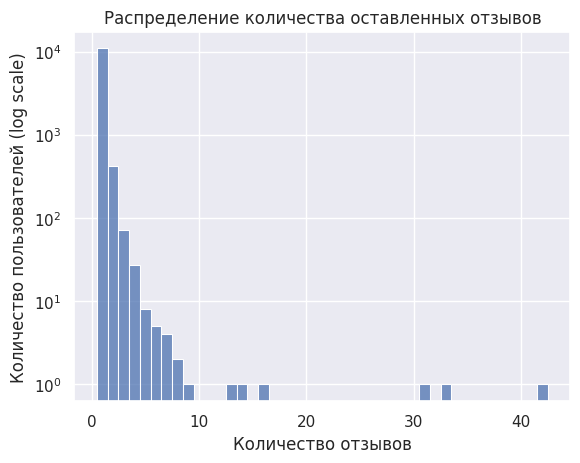

In [ ]:
# @title 📊 Распределение количества оставленных отзывов (график)
ax = sns.histplot(x=user_review_counts, discrete=True)
ax.set(ylabel='Количество пользователей (log scale)', xlabel='Количество отзывов')
ax.set_yscale('log')
ax.set_title('Распределение количества оставленных отзывов');

In [ ]:
quant = len(user_review_counts[user_review_counts>1]) / len(user_review_counts)
print(f'Процент пользователей, оставивших более 1 отзыва: {quant:.1%}')

quant = len(user_review_counts[user_review_counts>10]) / len(user_review_counts)
print(f'Процент пользователей, оставивших более 10 отзывов: {quant:.1%}')

Процент пользователей, оставивших более 1 отзыва: 4.8%
Процент пользователей, оставивших более 10 отзывов: 0.1%


Распределение скошено вправо: 95% пользователей оставили только один отзыв, остальные 5% -- от 2 до 42. Рассмотрим 10 самых активных пользователей.

In [ ]:
print('Топ-10 самых активных:')
user_review_counts.head(10)

Топ-10 самых активных:


,count
user_name,
bambinito,42
user-420212389169,33
user-831711940237,31
Pharaohadynasty1,16
Aleks8888,14
user-460111766992,13
satakn,9
son18,8
Реверс,8


Менее 5% пользователей оставили 2 и более отзыва. Максимальное количество отзывов, оставленное одним пользователем -- 42. Рассмотрим, какие оценки поставили 10 наиболее активных пользователей и каким банкам.

In [ ]:
# подготавливаем данные, которые будем отображать
top10_users = df[df['user_name'].isin(user_review_counts.head(10).index)]
top10_users['usr_bank'] = top10_users['user_name'] + '/' + top10_users['bank'].apply(lambda s: s[:7] + '...' + s[-6:] if len(s)>16 else s)

/tmp/ipykernel_80820/1958103136.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  top10_users['usr_bank'] = top10_users['user_name'] + '/' + top10_users['bank'].apply(lambda s: s[:7] + '...' + s[-6:] if len(s)>16 else s)


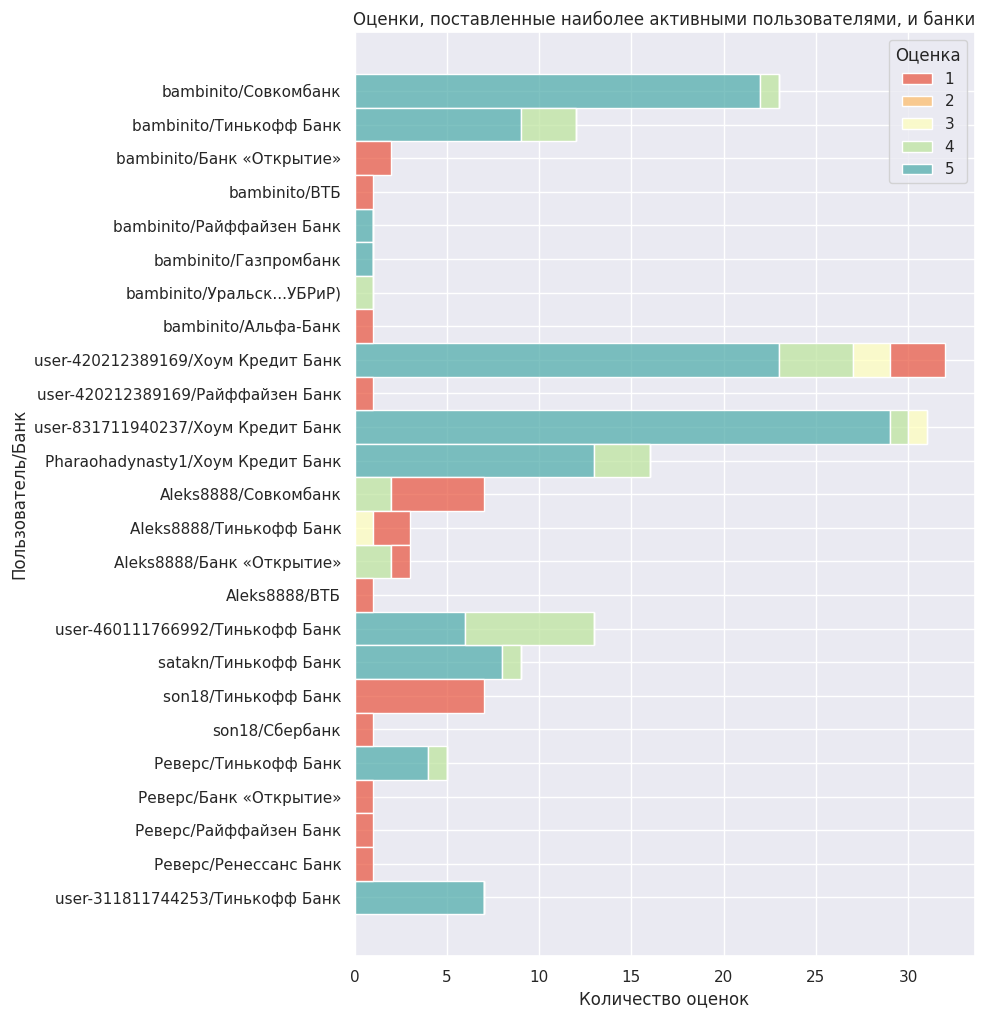

In [ ]:
# @title 📊 Оценки 10-ти наиболее активных пользователей (график)

order = []
for u in user_review_counts.head(10).index:
    order.extend(top10_users[top10_users['usr_bank'].str.startswith(u)]['usr_bank'].value_counts().index)
top10_users = top10_users.set_index('usr_bank').loc[order].reset_index()

# визуализация
fig, ax = plt.subplots(figsize=(8, 12))
sns.histplot(
    data=top10_users,
    y='usr_bank',
    hue='rating_value',
    multiple='stack',
    palette=sns.color_palette('Spectral', 5),
    hue_order=[1,2,3,4,5],
    # legend=False,
    ax=ax
)
sns.move_legend(ax, title='Оценка', loc='best')
ax.set_title('Оценки, поставленные наиболее активными пользователями, и банки')
ax.set(ylabel='Пользователь/Банк', xlabel='Количество оценок');

4 наиболее активных пользователя ставили преимущественно положительные оценки:
- bambinito: Совкомбанк и Тинькофф Банк
- user-420212389169: Хоум Кредит Банк
- user-831711940237: Хоум Кредит Банк
- Pharaohadynasty1: Хоум Кредит Банк

## Распределение отзывов по времени

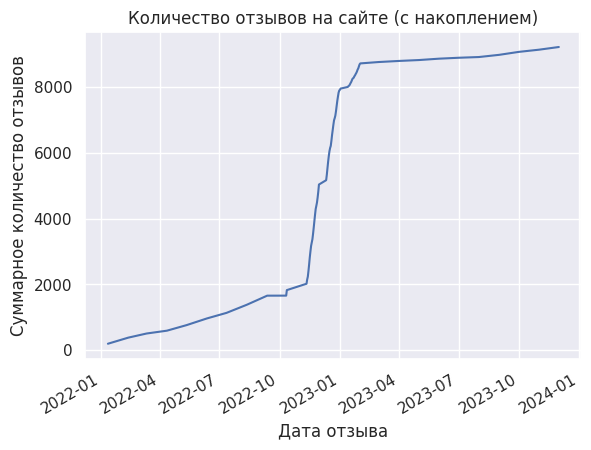

In [ ]:
# @title 📊 Количество отзывов с накоплением (график)
ax = df[df['bank'].isin(topn.index)]['review_dttm'].value_counts().sort_index().cumsum().plot.line()
ax.set_title('Количество отзывов на сайте (с накоплением)')
ax.set(ylabel='Суммарное количество отзывов', xlabel='Дата отзыва');

Мы установили, что несмотря на продолжительный период, в течение которого были собраны отзывы (почти 2 года), "активных" дней всего 87, что вызывает подозрения. Из графика выше также видно резкий скачок с конца 2022 по начало 2023 года.

Рассмотрим календарь активности.

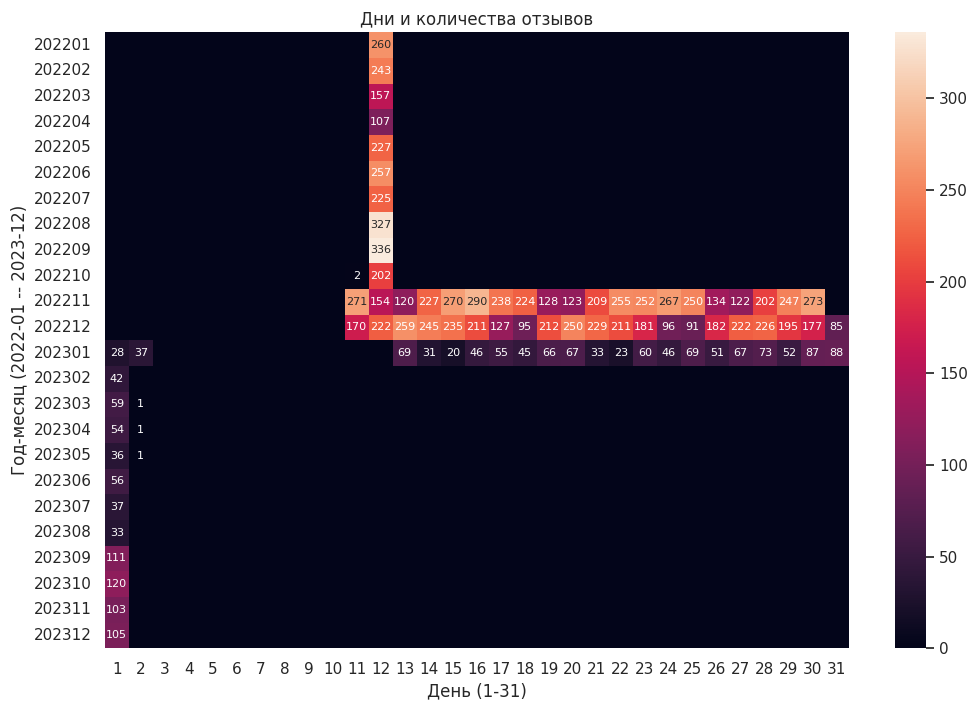

In [ ]:
# @title 📊 Календарь активности (график)

# создаем календарь дней за указанный период
all_dates = []
for y in (2022, 2023):
    for m in range(1,13):
        for d in range(1,32):
            all_dates.append(y*10000+m*100+d)

# объединяем все дни с днями, когда были оставлены отзывы
dates_df = pd.merge(
    left=pd.DataFrame(index=all_dates),
    right=df['review_dttm'].apply(lambda d: d.year*10000+d.month*100+d.day).value_counts().sort_index(),
    how='outer',
    left_index=True,
    right_index=True
).fillna(0)
dates_df['year_month'] = dates_df.index//100
dates_df['day'] = dates_df.index%100


# визуализируем "календарь": по оси x -- дни, по оси y -- год и месяц
fig, ax = plt.subplots(figsize=(12,8))
pivot = dates_df.pivot(index="year_month", columns="day", values="count")

# в аннотации оставляем только значения >0
annotations = pivot.astype(int).where(
    pivot > 0,
    ""
)

# тепловая карта
sns.heatmap(data=pivot, annot=annotations, fmt='', annot_kws={"fontsize":8}, ax=ax)

ax.set_title('Дни и количества отзывов')
ax.set(ylabel='Год-месяц (2022-01 -- 2023-12)', xlabel='День (1-31)');

Из календаря видим, что в датасет вошли отзывы, оставленные
- 12 числа каждого месяца с января по октябрь 2022 года,
- с 11 по 30/31 число в ноябре и декабре 2022 года
- 1 числа каждого месяца с января по декабрь 2023 года
- 2 числа, а также с 13 по 31 января 2023 года

Проверка отзывов на сайте показала, что отсутствие отзывов за определенные периоды это особенность (ошибка?) сбора данных, а не сайта.

Также в течение трехнедельных "активных" периодов в конце 2022 года и январе 2023 года заметна сезонность: наибольшая активность приходится на 5 рабочих дней с падением активности на выходных, однако в январе активность в среднем меньше, чем в предыдущие два месяца.

Из тепловой карты мы также видим, что из всех "активных" дней выделяются 12 число августа и сентября 2022 года. Из-за неполноты данных мы не можем достоверно проверить, является ли эта разница значимой, но ничто не мешает нам рассмотреть этот всплеск подробнее.

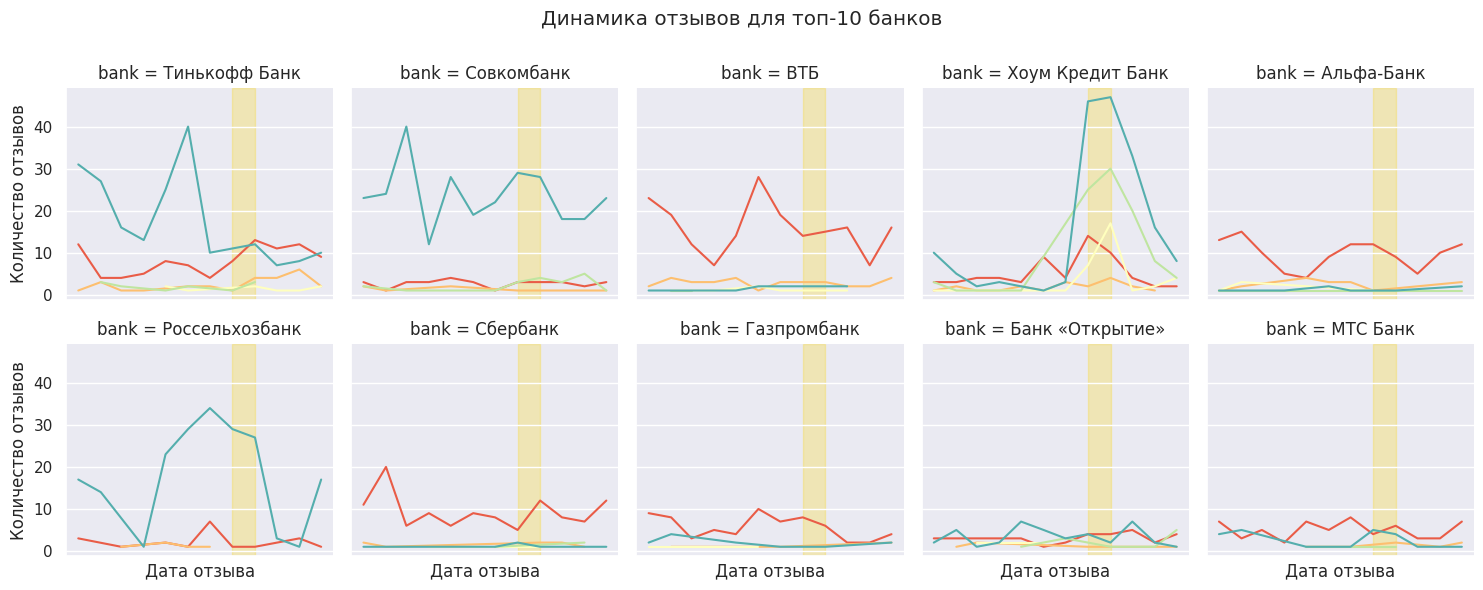

In [ ]:
# @title 📊 Количество отзывов по дням для топ-10 банков (график)
# @markdown График показывает количества отзывов для каждого банка из топ-10 на 12 число каждого месяца с января по декабрь 2022 года. Желтым выделен интересующий нас сегмент -- 12 августа и 12 сентября, когда наблюдался всплеск активности.

# считаем отзывы, группируя по дате, банку и оценке
topn_2022 = df[(df['bank'].isin(topn.index)) & (df['review_dttm'].dt.day==12)].groupby(['review_dttm', 'bank', 'rating_value'])['review'].count().reset_index()

g = sns.FacetGrid(data=topn_2022, col='bank', hue='rating_value', palette=sns.color_palette('Spectral',5), col_order=topn.index, col_wrap=5)
g.map(sns.lineplot, 'review_dttm', 'review')

for ax in g.axes.flat:
    ax.axvspan(
        '2022-08-12',
        '2022-09-12',
        color="gold",
        alpha=0.25,
        zorder=0
    )

g.set(xticks=[], xlabel='Дата отзыва', ylabel='Количество отзывов')
plt.suptitle('Динамика отзывов для топ-10 банков')
plt.tight_layout(rect=[0, 0, 1, 0.98]);

In [ ]:
print('Топ банков по количеству оставленных отзывов 12 августа и 12 сентября 2022 года')
df[(df['review_dttm'].astype(str).isin(['2022-08-12','2022-09-12']))]['bank'].value_counts().head(5)

Топ банков по количеству оставленных отзывов 12 августа и 12 сентября 2022 года


,count
bank,
Хоум Кредит Банк,202
Совкомбанк,71
Россельхозбанк,58
Тинькофф Банк,55
ВТБ,35


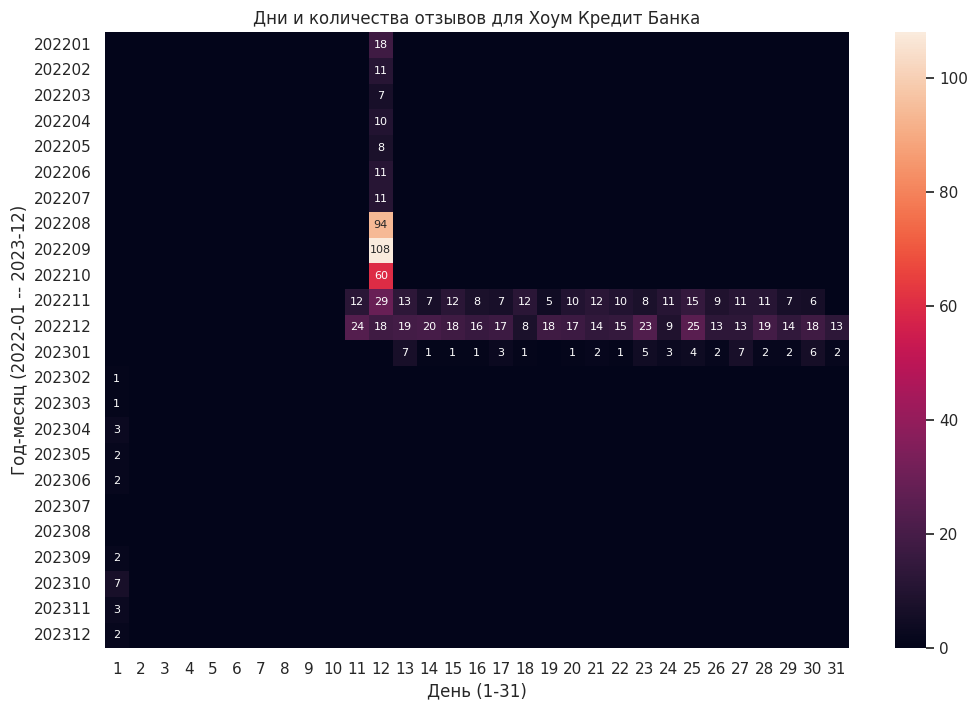

In [ ]:
# @title 📊 Календарь отзывов для Хоум Кредит Банка (график)

# объединяем все дни с днями, когда были оставлены отзывы
dates_hcb = pd.merge(
    left=pd.DataFrame(index=all_dates),
    right=df[df['bank']=='Хоум Кредит Банк']['review_dttm'].apply(lambda d: d.year*10000+d.month*100+d.day).value_counts().sort_index(),
    how='outer',
    left_index=True,
    right_index=True
).fillna(0)
dates_hcb['year_month'] = dates_hcb.index//100
dates_hcb['day'] = dates_hcb.index%100

# визуализируем "календарь": по оси x -- дни, по оси y -- год и месяц
pivot = dates_hcb.pivot(index="year_month", columns="day", values="count")

# в аннотации оставляем только значения >0
annotations = pivot.astype(int).where(
    pivot > 0,
    ""
)

# тепловая карта
fig, ax = plt.subplots(figsize=(12,8))
sns.heatmap(data=pivot, annot=annotations, fmt='', annot_kws={"fontsize":8}, ax=ax)

ax.set_title('Количества отзывов на Хоум Кредит Банк по дням')
ax.set(ylabel='Год-месяц (2022-01 -- 2023-12)', xlabel='День (1-31)');

В календаре, визуализированном выше наблюдается повышенная активность 12 августа и 12 сентября 2022 года. Детализировав активность по банкам, мы увидели в указанные дни (а также 12 октября) резкий рост и затем падение количества положительных (оценки 4,5) и в меньшей степени нейтральных (оценка 3) и отрицательных (оценка 1) отзывов для Хоум Кредит Банка. Это же иллюстрирует тепловая карта.

## Корреляции
Для измерения корреляции используем коэффициент Кенделла, поскольку в данных есть выбросы.

                 review_views  review_comments  rating_value  review_len
review_views         1.000000         0.117641     -0.226117    0.134948
review_comments      0.117641         1.000000     -0.362611    0.135550
rating_value        -0.226117        -0.362611      1.000000   -0.332466
review_len           0.134948         0.135550     -0.332466    1.000000


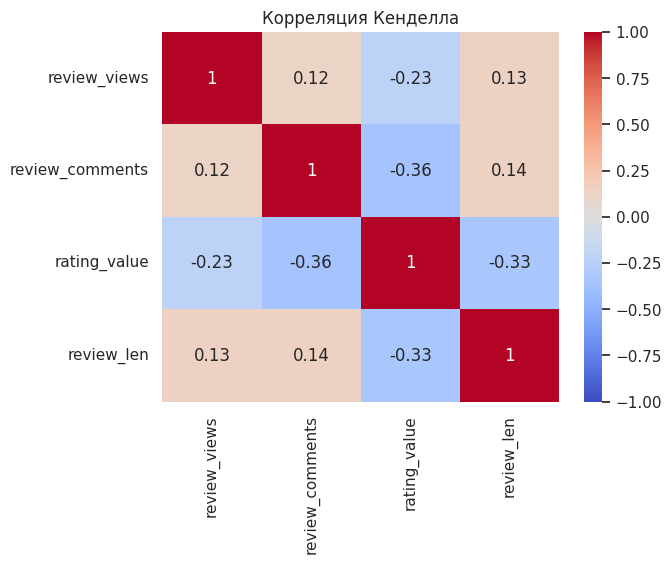

In [ ]:
# @title 📊 Корреляционная матрица (график)
# корреляционная матрица
cor_matrix = df.corr(numeric_only=True, method='kendall')
print(cor_matrix)

# визуализация
ax = sns.heatmap(cor_matrix, cmap="coolwarm", annot=True, vmin=-1, vmax=1)
ax.set_title('Корреляция Кенделла');

Из корреляционной матрицы видим две умеренные корреляции:
- между длиной отзыва и значением оценки
- между значением оценки и количеством ответных комментариев.

Визуализируем их и измерим, установим $\alpha = 0.05$.

Kendall τ = -0.332
p = 0


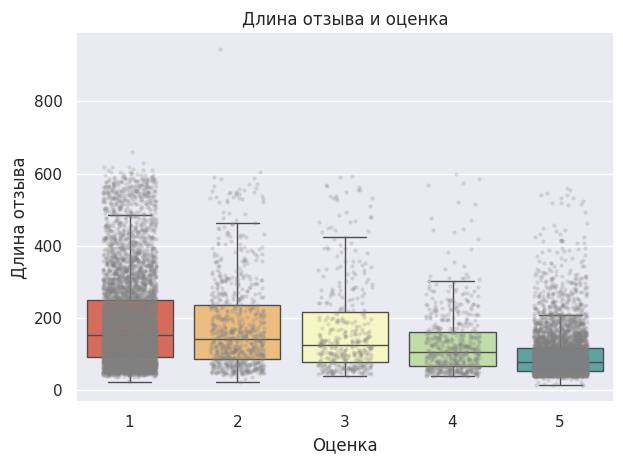

In [ ]:
# @title 📊 Корреляция Кенделл между длиной отзыва и оценкой (график)
tau, p_value = kendalltau(
    df["review_len"],
    df["rating_value"]
)
print(f"Kendall τ = {tau:.3f}\np = {p_value:.3g}")

# boxplot
sns.boxplot(
    data=df,
    x="rating_value",
    y="review_len",
    hue="rating_value",
    showfliers=False,
    legend=False,
    palette=sns.color_palette('Spectral', 5)
)

# точки
sns.stripplot(
    data=df,
    x="rating_value",
    y="review_len",
    color="grey",
    alpha=0.25,
    jitter=0.25,
    size=3
)

plt.xlabel("Оценка")
plt.ylabel("Длина отзыва")
plt.title("Длина отзыва и оценка")
plt.tight_layout()
plt.show()

In [ ]:
# Вычисляем доверительный интервал при помощи бустрепа
x = df["rating_value"]
y = df["review_len"]

result = bootstrap(
    data=(x, y),
    statistic=tau_statistic,
    paired=True,
    vectorized=False,
    n_resamples=1000,
    confidence_level=0.95,
    rng=np.random.default_rng(42)
)

print(f"CI [{result.confidence_interval.low:.3f}, {result.confidence_interval.high:.3f}]")

CI [-0.344, -0.321]


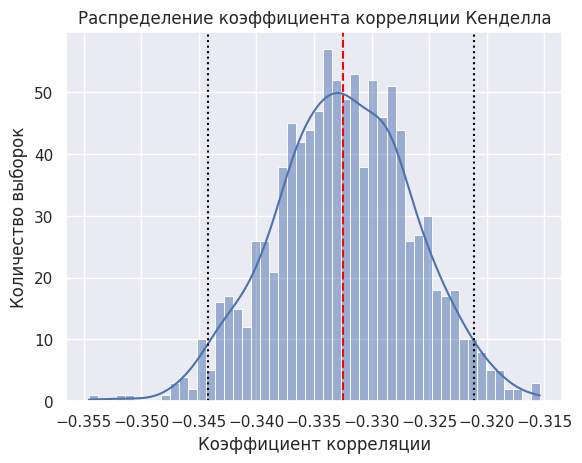

In [ ]:
# @title 📊 Доверительный интервал коэффициента корреляции Кенделла между длиной отзыва и оценкой (график)
ax = sns.histplot(result.bootstrap_distribution, bins=50, kde=True)
plt.axvline(tau, color="red", linestyle="--")
plt.axvline(result.confidence_interval.low, color="black", linestyle=":")
plt.axvline(result.confidence_interval.high, color="black", linestyle=":")
ax.set(xlabel="Коэффициент корреляции", ylabel='Количество выборок')
plt.title("Распределение коэффициента корреляции Кенделла");

Коэффициент корреляции Кенделла $​\tau=-0.33$, 95% доверительный интервал CI [0.28, 0.34], p<<0.05, n=12,392 при $\alpha$=0.05.

Наблюдается слабая/умеренная обратная корреляция между длиной отзыва и оценкой.

Kendall τ = -0.363
p = 0


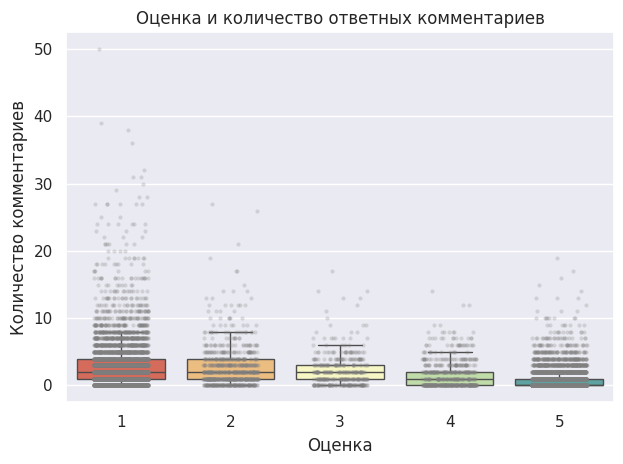

In [ ]:
# @title 📊 Корреляция Кенделл между оценкой и количеством ответных комментариев (график)

tau, p_value = kendalltau(
    df["review_comments"],
    df["rating_value"]
)
print(f"Kendall τ = {tau:.3f}\np = {p_value:.3g}")

# boxplot
sns.boxplot(
    data=df,
    x="rating_value",
    y="review_comments",
    hue="rating_value",
    showfliers=False,
    legend=False,
    palette=sns.color_palette('Spectral', 5)
)

# точки
sns.stripplot(
    data=df,
    x="rating_value",
    y="review_comments",
    color="grey",
    alpha=0.25,
    jitter=0.25,
    size=3
)

# plt.yscale("log")
plt.xlabel("Оценка")
plt.ylabel("Количество комментариев")
plt.title("Оценка и количество ответных комментариев")
plt.tight_layout()
plt.show()

In [ ]:
# Вычисляем доверительный интервал при помощи бустрепа
x = df["rating_value"]
y = df["review_comments"]

result = bootstrap(
    data=(x, y),
    statistic=tau_statistic,
    paired=True,
    vectorized=False,
    n_resamples=1000,
    confidence_level=0.95,
    rng=np.random.default_rng(42)
)

print(f"CI [{result.confidence_interval.low:.3f}, {result.confidence_interval.high:.3f}]")

CI [-0.375, -0.349]


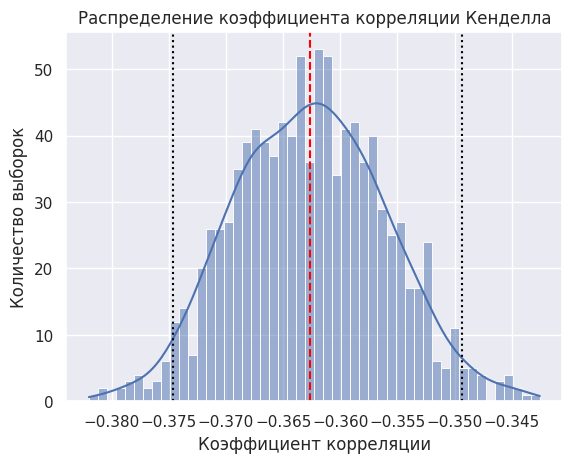

In [ ]:
# @title 📊 Доверительный интервал коэффициента корреляции Кенделла между оценкой и количеством ответных комментариев (график)
ax = sns.histplot(result.bootstrap_distribution, bins=50, kde=True)
plt.axvline(tau, color="red", linestyle="--")
plt.axvline(result.confidence_interval.low, color="black", linestyle=":")
plt.axvline(result.confidence_interval.high, color="black", linestyle=":")
ax.set(xlabel="Коэффициент корреляции", ylabel='Количество выборок')
plt.title("Распределение коэффициента корреляции Кенделла");

Коэффициент корреляции Кенделла $​\tau=-0.36$, 95% доверительный интервал CI [-0.375, -0.349], p<<0.05, n=12,392 при $\alpha$=0.05.

Наблюдается слабая/умеренная обратная корреляция между оценкой и количеством ответных комментариев.

# Выводы

Датасет включает 12 392 отзыва на 86 банков, собранные в период с 12 января 2022 года по 1 декабря 2023 года. Датасет включает непосредственно текст отзыва, заголовок, никнейм автора на сайте, дату отзыва, название банка, рейтинг, поставленный пользователем банку, количество просмотров и ответов, а также численные оценки по отдельным критериям и длину отзыва -- последние вероятно были добавлены самим автором датасета.

В датасете наблюдается небольшая доля пропусков в заголовке отзыва и никнеймах авторов. Поскольку мы не знаем, как именно был организован сбор данных, мы не можем указать на точную причину пропусков. Однако, у нас получилось выявить их закономерности.

Несмотря на продолжительный период между самой ранней и самой поздней датой отзыва (688 дней), в датасете собраны отзывы, всего лишь за 87 дней, причем в них также наблюдается паттерн.

Банки несбалансированы по количеству оставленных отзывов: оценки всего для десяти из них составляют более 74% всех отзывов. Распределение оценок для всех банков в совокупности отличается полярностью и сравнительной сбалансированностью, тогда как для каждого отдельного банка при сохранении полярности теряется сбалансированность: у одних банков абсолютное большинство оценок крайне отрицательные, у других -- крайне положительные.

95% пользователей оставили всего 1 отзыв, максимальное количество отзывов, оставленное одним пользователем -- 42. Десять наиболее активных пользователей оставили в большинстве своем положительные оценки, которые распределились между Совкомбанком, Тинькофф Банком, Хоум Кредит Банком.

Повышенная активность наблюдалась 12 августа и 12 сентября 2022 года. Тогда в особенности выросло количество оценок для Хоум Кредит Банка -- в большей степени положительных, чем отрицательных.

Мы также рассмотрели две обратные корреляции -- между длиной отзыва и оценкой и оценкой и количеством ответов на отзыв. Обе несут умеренный характер.
